# FrameSignal Lab: Proxy Validation
Synthetic household-randomized presentation policies. Primary target: assigned-household return during days 29-56, not Netflix retention. Qualified starts is primary; viewing days is the predefined alternative. Completion among starters is descriptive only. Fixed v1.0 protocol; no learned weights or optional stopping.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'configs' / 'analysis_plan.json').exists())
sys.path.insert(0, str(root / 'backend'))
from app.analysis.workbench import PLAN, analyze, validation_suite
PLAN

{'version': '1.0',
 'seed': 20261031,
 'assignment_unit': 'household',
 'primary_target': 'returned_d29_56',
 'primary_candidate': 'qualified_starts',
 'alternative_candidate': 'viewing_days',
 'short_window_days': 14,
 'target_window_days': [29, 56],
 'households_per_experiment': 2000,
 'experiments_per_split': 9,
 'splits': ['train', 'validation', 'heldout'],
 'practical_target_effect': 0.02,
 'familywise_alpha': 0.05,
 'candidate_alpha': 0.025,
 'agreement_draws': 1000,
 'operating_repetitions': 1000,
 'minimum_agreement_lower_bound': 0.8,
 'decision': 'No deployment on a proxy alone; target evidence governs policy decisions.',
 'stopping_rule': 'Fixed horizon; no repeated significance checks or outcome-based extension.',
 'learning': 'No learned weights in MVP; candidates and thresholds frozen before held-out runs.'}

In [2]:
runs = {name: analyze(name, PLAN['households_per_experiment'], PLAN['seed']) for name in ['helpful', 'unrelated', 'misleading']}
rows = []
for name, run in runs.items():
    assert run['sql']['passed']
    for metric, result in run['metrics'].items():
        rows.append({'scenario': name, 'metric': metric, 'effect': result['effect'], 'lower': result['lower'], 'upper': result['upper'], 'causal_itt': result['causal']})
pd.DataFrame(rows)

,scenario,metric,effect,lower,upper,causal_itt
0,helpful,qualified_starts,1.500000,1.246748,1.753252,True
1,helpful,viewing_days,1.132000,0.946347,1.317653,True
2,helpful,watch_minutes,103.065569,89.912985,116.218153,True
3,helpful,completion,0.531605,0.491702,0.574335,False
4,helpful,returned_d29_56,0.060000,0.016407,0.103593,True
5,unrelated,qualified_starts,1.921000,1.649513,2.192487,True
6,unrelated,viewing_days,1.412000,1.220801,1.603199,True
7,unrelated,watch_minutes,70.249556,58.886877,81.612234,True
8,unrelated,completion,-0.159229,-0.187807,-0.128960,False
9,unrelated,returned_d29_56,-0.010000,-0.053858,0.033858,True


In [3]:
suite = validation_suite(PLAN['seed'])
assert suite['leakage_check']
assert suite['unique_households'] == 54000
assert suite['learned_weights'] is None
heldout = [row for row in suite['experiments'] if row['split'] == 'heldout']
pd.DataFrame([{'experiment': row['id'], 'scenario': row['scenario'], 'starts_return_correlation': row['prediction']['qualified_starts'], 'starts_effect': row['effects']['qualified_starts']['effect'], 'return_effect': row['effects']['returned_d29_56']['effect'], 'oracle_return_effect': row['truth_return_effect']} for row in heldout])

,experiment,scenario,starts_return_correlation,starts_effect,return_effect,oracle_return_effect
0,heldout-01,helpful,0.044589,0.946,0.028,0.036
1,heldout-02,unrelated,0.021090,1.316,-0.004,0.000
2,heldout-03,misleading,0.039739,1.451,-0.074,-0.036
3,heldout-04,helpful,0.037043,1.452,0.059,0.060
4,heldout-05,unrelated,0.024121,1.822,-0.023,0.000
5,heldout-06,misleading,0.003877,2.092,-0.063,-0.060
6,heldout-07,helpful,0.059988,1.892,0.105,0.084
7,heldout-08,unrelated,0.085860,2.371,0.048,0.000
8,heldout-09,misleading,-0.008076,2.131,-0.087,-0.084


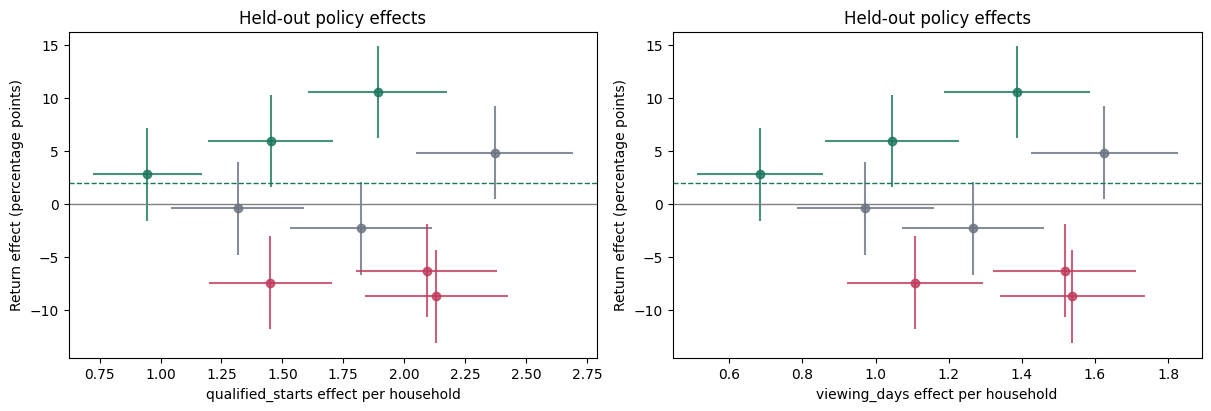

,observed_agreement,lower,upper,noise_lower,noise_upper,n_experiments,resolved_target_experiments,oracle_nonnull_agreement,oracle_null_proxy_positive,oracle_null_experiments,draws,warning
qualified_starts,0.444444,0.111111,0.777778,0.222222,0.777778,9,6,0.5,3,3,1000,Experiment bootstrap interval is descriptive w...
viewing_days,0.444444,0.111111,0.777778,0.222222,0.777778,9,6,0.5,3,3,1000,Experiment bootstrap interval is descriptive w...


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
colors = {'helpful': '#19765c', 'unrelated': '#6b7280', 'misleading': '#bf395a'}
for axis, metric in zip(axes, ['qualified_starts', 'viewing_days']):
    for row in heldout:
        candidate = row['effects'][metric]
        target = row['effects']['returned_d29_56']
        axis.errorbar(candidate['effect'], 100 * target['effect'], xerr=[[candidate['effect'] - candidate['lower']], [candidate['upper'] - candidate['effect']]], yerr=[[100 * (target['effect'] - target['lower'])], [100 * (target['upper'] - target['effect'])]], fmt='o', color=colors[row['scenario']], alpha=0.8)
    axis.axhline(0, color='gray', linewidth=1)
    axis.axhline(2, color='#19765c', linestyle='--', linewidth=1)
    axis.set(xlabel=f'{metric} effect per household', ylabel='Return effect (percentage points)', title='Held-out policy effects')
plt.show()
pd.DataFrame(suite['agreement']['heldout']).T

In [5]:
pd.DataFrame([{'scenario': name, 'metric': metric, **values} for name, run in runs.items() for metric, values in run['prediction']['metrics'].items()])

,scenario,metric,correlation,lower,upper,within_arm
0,helpful,qualified_starts,0.062279,0.014453,0.105813,"[0.02513344179287981, 0.06341792015592634]"
1,helpful,viewing_days,0.062803,0.020827,0.101326,"[0.03174759736689762, 0.05991992056184087]"
2,unrelated,qualified_starts,0.046792,-0.000462,0.090446,"[-0.004119266449183934, 0.08741110418799015]"
3,unrelated,viewing_days,0.045769,0.006735,0.085339,"[-0.011175079367066324, 0.09592148141150118]"
4,misleading,qualified_starts,0.027948,-0.017400,0.070589,"[0.0026153118272278677, 0.067456708305827]"
5,misleading,viewing_days,0.024939,-0.025050,0.070297,"[0.009015151714722763, 0.06296125603537288]"


## Decision and limitations
Reject a universal qualified-starts surrogate: starts can rise when the known longer-horizon effect is zero or negative. Viewing days is not certified. Keep direct return for decisions; require its lower interval to exceed +2 pp before advancing. Positive household association is confounded by affinity and is not causal surrogacy. Nine held-out experiments limit support. Experiment bootstrap and correlated Gaussian effect-noise sensitivity are descriptive, not definitive surrogate inference. Null-effect signs are unstable; inspect oracle non-null agreement separately. Self-review only; no peer feedback occurred. See the research plan for verified Netflix methodological starting points, not internal metric claims.

In [6]:
from pathlib import Path
import sys
import pandas as pd
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'configs' / 'analysis_plan.json').exists())
sys.path.insert(0, str(root / 'backend'))
from framesignal_metrics import __version__ as metric_library_version, calculate_household_metrics
from app.metrics.registry import household_metrics
from app.simulations.generator import simulate
parity_data = simulate('misleading', n=200, seed=21)
library_frame = calculate_household_metrics(parity_data.households, parity_data.events, parity_data.exposures)
pd.testing.assert_frame_equal(library_frame, household_metrics(parity_data), check_exact=True)
assert len(library_frame) == 200
assert library_frame.loc[~library_frame.starter, 'completion'].isna().all()
print(f'Shared library {metric_library_version}: exact parity; all 200 assigned households retained. Educational calculation only, not surrogate approval.')

Shared library 1.0.0: exact parity; all 200 assigned households retained. Educational calculation only, not surrogate approval.
